## MakeMore is a character level language model , meaning that it models / predicts the next character in a sequence

In [1]:
words = open('names.txt','r').read().splitlines()

In [2]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
len(words)

32033

In [4]:
min_len = min(len(w) for w in words)
min_len

2

In [5]:
max_len = max(len(w) for w in words)
max_len

15

## Bigram

In [6]:
from collections import Counter
b = Counter()
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1,ch2 in zip(chs, chs[1:]):
        bigrams = (ch1,ch2)
        b[bigrams] += 1
        #print(ch1,ch2)


In [7]:
b

Counter({('n', '<E>'): 6763,
         ('a', '<E>'): 6640,
         ('a', 'n'): 5438,
         ('<S>', 'a'): 4410,
         ('e', '<E>'): 3983,
         ('a', 'r'): 3264,
         ('e', 'l'): 3248,
         ('r', 'i'): 3033,
         ('n', 'a'): 2977,
         ('<S>', 'k'): 2963,
         ('l', 'e'): 2921,
         ('e', 'n'): 2675,
         ('l', 'a'): 2623,
         ('m', 'a'): 2590,
         ('<S>', 'm'): 2538,
         ('a', 'l'): 2528,
         ('i', '<E>'): 2489,
         ('l', 'i'): 2480,
         ('i', 'a'): 2445,
         ('<S>', 'j'): 2422,
         ('o', 'n'): 2411,
         ('h', '<E>'): 2409,
         ('r', 'a'): 2356,
         ('a', 'h'): 2332,
         ('h', 'a'): 2244,
         ('y', 'a'): 2143,
         ('i', 'n'): 2126,
         ('<S>', 's'): 2055,
         ('a', 'y'): 2050,
         ('y', '<E>'): 2007,
         ('e', 'r'): 1958,
         ('n', 'n'): 1906,
         ('y', 'n'): 1826,
         ('k', 'a'): 1731,
         ('n', 'i'): 1725,
         ('r', 'e'): 1697,
      

In [8]:
sorted(b.items(), key=lambda x: x[1], reverse=True)

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [9]:
%pip install torch
import torch

You should consider upgrading via the '/Users/Fares/Desktop/ml_projects/neural_networks_0_to_hero/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [10]:
bi_grams = torch.zeros(28,28, dtype=torch.int32)
bi_grams

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [11]:
chars = sorted(list(set(''.join(words))))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [12]:
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27

In [13]:

for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1,ch2 in zip(chs, chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        bi_grams[idx1,idx2] += 1
        #print(ch1,ch2)

In [14]:
bi_grams

tensor([[   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0],
        [   0,  556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568,
         2528, 1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,
          182, 2050,  435, 6640],
        [   0,  321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,
          103,    0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,
            0,   83,    0,  114],
        [   0,  815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,
          116,    0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,
            3,  104,    4,   97],
        [   0, 1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,
           60,   30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,
            0,  317,    1,  516],
        [   0,  679,

In [15]:
%pip install matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
%matplotlib inline

You should consider upgrading via the '/Users/Fares/Desktop/ml_projects/neural_networks_0_to_hero/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [16]:
import numpy as np

KeyError: 0

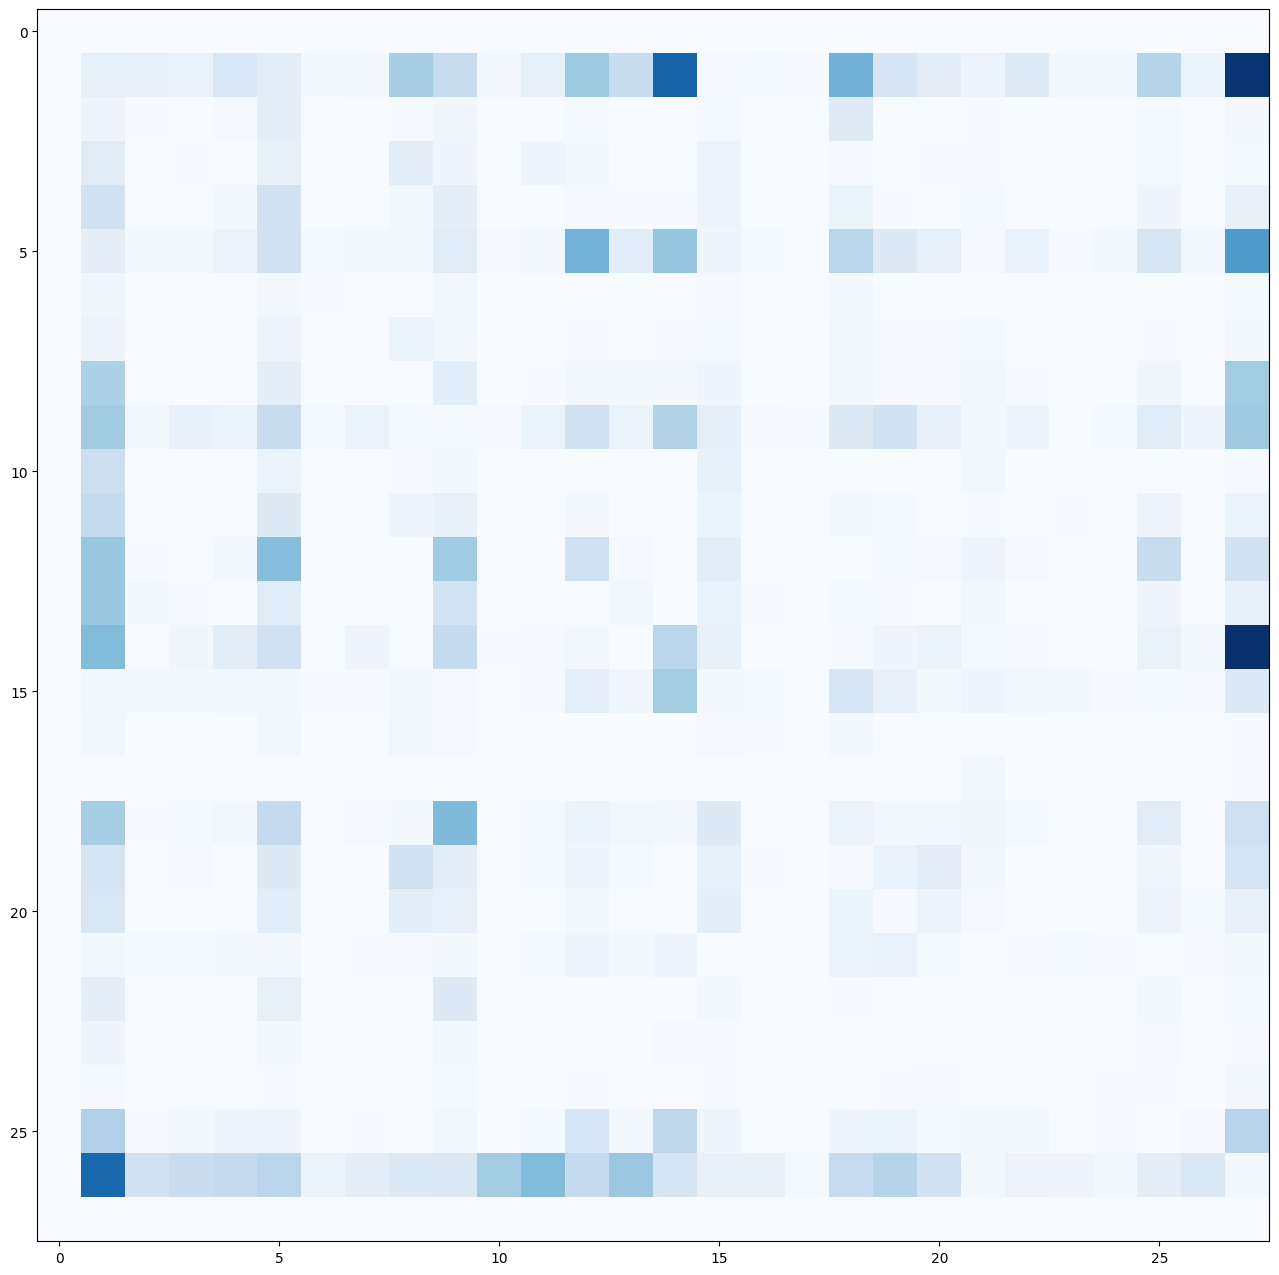

In [ ]:
itos = {i:s for s,i in stoi.items()}

import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(bi_grams.detach().cpu().numpy(), cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos.get(i, "") + itos.get(j, "")
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, bi_grams[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [ ]:
%pip install numpy